In [69]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.special import gamma
import matplotlib.pyplot as plt
from IPython.display import display, Math

In [70]:
fp = Path("/Users/nhoojaroy/Desktop/Class-Projects/Homework_3_code/circle_data.csv")
df = pd.read_csv(fp)
print(df.shape)
print(df.columns)
print(df.head(20))

(49, 2)
Index(['-3.9265307', '5.7992251'], dtype='object')
    -3.9265307  5.7992251
0    -3.171616   7.313062
1    -1.611599   7.559243
2    -2.667940   7.691135
3    -1.729971   5.511308
4    -2.218502   7.744210
5    -2.061850   7.709185
6    -1.477450   6.054910
7    -3.209541   7.517087
8    -2.013939   7.604547
9    -2.096539   5.135421
10   -2.841485   5.067184
11   -3.551632   7.391073
12   -2.332501   7.694923
13   -1.688935   5.346929
14   -1.493715   7.347366
15   -1.310394   6.871547
16   -1.308242   6.784201
17   -1.522137   5.728363
18   -1.862180   7.763315
19   -2.878418   7.767726


### Problem 11.2
We are given a function $f(x) = \frac{1}{x}$ and are asked to estimate this function using the basis set, $e = \{e^x, \sin x, \Gamma(x)\}$ solving the least squares problem for a matrix built using a discrete grid of x on the interval $[1,2]$. We know all of the above functions are well defined in this interval, so we first discretize the interval, build the matrix with columns $\sin x_i, e^x_i, \Gamma(x_i)$ where $i = 1, \dots, n$. We can choose $h$, the interval length, as $h =\frac{1}{n}$, which gives us a discrete grid to build a matrix. The following code blocks do exactly this.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

/Users/nhoojaroy/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


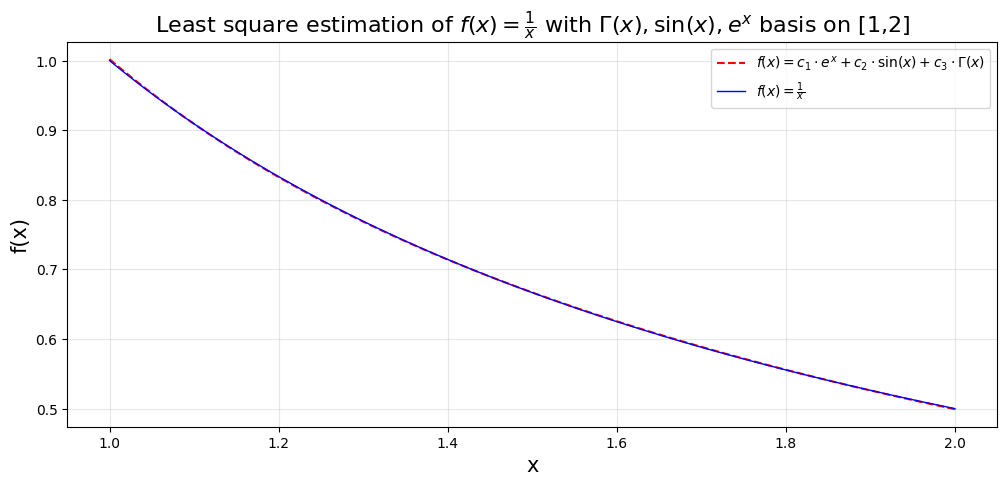

In [79]:
# a)
n = 100000000
def l2_fit(f,basis,a,b,N=n):
    x = np.linspace(a,b,N)
    A = np.column_stack([phi(x) for phi in basis])
    c = np.linalg.lstsq(A,f(x),rcond=None)[0]
    res = np.linalg.norm(f(x) - A @ c) * np.sqrt((b - a)/N)
    return c, res, A


basis = [np.exp, np.sin, gamma]

c, res, A = l2_fit(lambda x: 1/x, basis , 1, 2)
display(Math(rf"\text{{Residual }} \|\epsilon\|_2 = {res:.6e}"))
display(Math(r"\text{Fit parameters } \vec{c} \text{ for } A\vec{c} = \vec{b}:"))
for i, ci in enumerate(c, 1):
    display(Math(rf"c_{{{i}}} = {ci:.6f}"))

x = np.linspace(1,2,n)
y_h = np.array(A @ c)

plt.figure(figsize=(12,5))
plt.plot(x, y_h, "--",label= r"$f(x) = c_1 \cdot e^x + c_2 \cdot \sin(x) + c_3 \cdot \Gamma(x)$", color = "red")
plt.plot(x, 1/x, label= r"$f(x) = \frac{1}{x}$", color = "blue", linewidth = 1)
plt.xlabel('x', fontsize = 15)
plt.ylabel('f(x)', fontsize= 15)
plt.title(r'Least square estimation of $f(x) = \frac{1}{x}$ with $\Gamma (x), \sin(x), e^x$ basis on [1,2]', size = 16)
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

### Problem 2:

Here we have a least square problem to estimate a circle, using a set of points that might not all fall neatly on a circle. We are trying to find a circle s.t. we minimize the residual between data points and the circle with radius R, and center $(x_c, y_c)$ chosen. Then as per the given objective in the question we now find the curve of best fit.

Expanding each squared term in the objective, we get:

$$(x_i - x_c)^2 + (y_i - y_c)^2 - R^2 = x_i^2 + y_i^2 - 2x_i x_c - 2y_i y_c + \left(x_c^2 + y_c^2 - R^2\right).$$

With the change of variable $w = x_c^2 + y_c^2 - R^2$, setting each residual to zero gives a linear equation in the unknowns $(x_c, y_c, w)$ for every data point:

$$2x_i \, x_c + 2y_i \, y_c - w = x_i^2 + y_i^2 .$$

This is the equation that is supplied to `np.column_stack` below: the coefficients $2x_i$, $2y_i$, $-1$ of the unknowns form the three columns of $A$, and the right-hand side $x_i^2 + y_i^2$ forms $\mathbf{b}$.
See in code below this is:
$$
\begin{align*}
&\texttt{A = np.column\_stack([2*x, 2*y, -np.ones\_like(x)])}\\
&\texttt{b = x**2 + y**2}
\end{align*}
$$
Then mathematically this is:
$$
\underbrace{\begin{bmatrix}
2x_1 & 2y_1 & -1 \\
2x_2 & 2y_2 & -1 \\
\vdots & \vdots & \vdots \\
2x_n & 2y_n & -1
\end{bmatrix}}_{A \,\in\, \mathbb{R}^{n \times 3}}
\underbrace{\begin{bmatrix}
x_c \\
y_c \\
w
\end{bmatrix}}_{\mathbf{x} \,\in\, \mathbb{R}^{3 \times 1}}
\approx
\underbrace{\begin{bmatrix}
x_1^2 + y_1^2 \\
x_2^2 + y_2^2 \\
\vdots \\
x_n^2 + y_n^2
\end{bmatrix}}_{\mathbf{b} \,\in\, \mathbb{R}^{n \times 1}}
$$

In [73]:
data = pd.read_csv("circle_data.csv", header=None).to_numpy()   # header=None keeps all 50 points
x, y = data[:, 0], data[:, 1]
A = np.column_stack([2*x, 2*y, -np.ones_like(x)])
b = x**2 + y**2
display(Math(rf"A \in \mathbb{{R}}^{{{A.shape[0]}\times {A.shape[1]}}}, \quad b \in \mathbb{{R}}^{{{b.shape[0]}\times 1}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

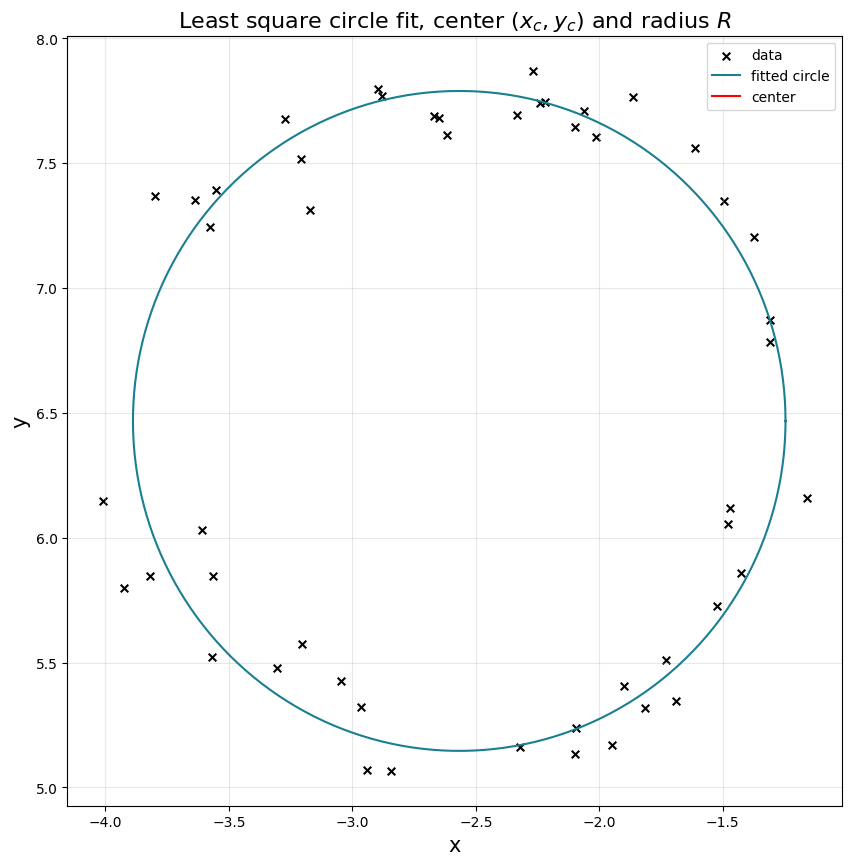

In [74]:
xc, yc, w = np.linalg.lstsq(A, b, rcond=None)[0]
R = np.sqrt(xc**2 + yc**2 - w)
display(Math(rf"x_c = {xc:.6f}"))
display(Math(rf"y_c = {yc:.6f}"))
display(Math(rf"R = {R:.6f}"))
display(Math(rf"\|Ax-b\|_2 = {np.linalg.norm(A @ np.array([xc, yc, w]) - b):.6f}"))

th = np.linspace(0, 2*np.pi, 400)

plt.figure(figsize=(10, 10))
plt.scatter(x, y, marker = "x", s=30, color="black", label="data")
plt.plot(xc + R*np.cos(th), yc + R*np.sin(th), color = "#197F91", label="fitted circle")
plt.plot(xc, yc, markersize=20, color ="red", label="center")
plt.xlabel('x', fontsize=15)
plt.ylabel('y', fontsize=15)
plt.title(r'Least square circle fit, center $(x_c, y_c)$ and radius $R$', size=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()